In [3]:
# Import libraries and prepare the data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

df = pd.read_csv("Nassau_Candy_Cleaned.csv")

# Parse order dates only; shipping dates are not yet verified
df["Order Date"] = pd.to_datetime(
    df["Order Date"], errors="coerce"
)

print("Dataset shape:", df.shape)
print("Customers:", df["Customer ID"].nunique())
print("Orders:", df["Order ID"].nunique())
print("Products:", df["Product ID"].nunique())

Dataset shape: (10194, 19)
Customers: 5044
Orders: 8549
Products: 15


In [4]:
# Statistical summary
numeric_cols = ["Sales", "Cost", "Gross Profit", "Units"]

display(df[numeric_cols].describe().round(2))

print("Total Sales: $", round(df["Sales"].sum(), 2))
print("Total Cost: $", round(df["Cost"].sum(), 2))
print("Total Gross Profit: $", round(df["Gross Profit"].sum(), 2))
print("Total Units Sold:", df["Units"].sum())

,Sales,Cost,Gross Profit,Units
count,10194.00,10194.00,10194.00,10194.00
mean,13.91,4.74,9.17,3.79
std,11.34,5.06,6.64,2.23
min,1.25,0.60,0.25,1.00
25%,7.20,2.40,4.90,2.00
50%,10.80,3.60,7.47,3.00
75%,18.00,5.70,12.25,5.00
max,260.00,130.00,130.00,14.00


Total Sales: $ 141783.63
Total Cost: $ 48340.83
Total Gross Profit: $ 93442.8
Total Units Sold: 38654


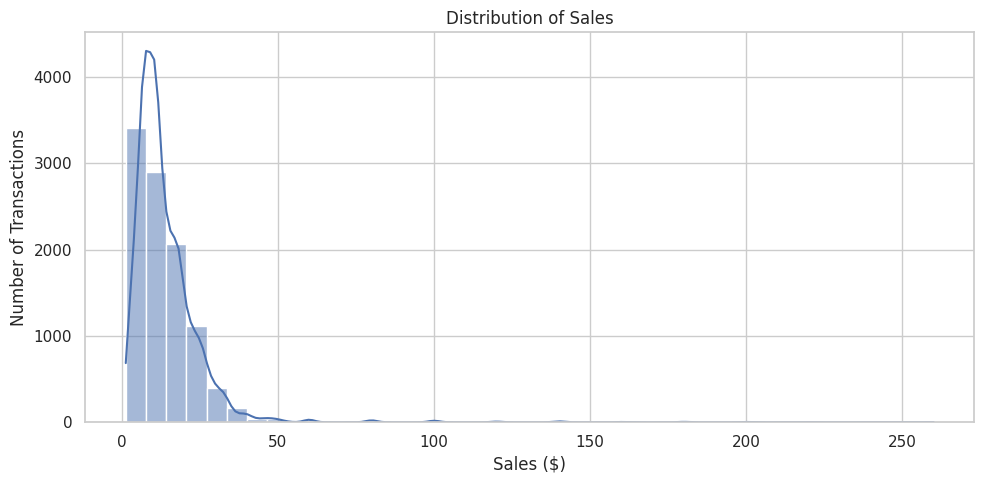

In [5]:
# Sales distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Sales",
    bins=40,
    kde=True
)

plt.title("Distribution of Sales")
plt.xlabel("Sales ($)")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

In [6]:
# Customer analysis
customer_summary = (
    df.groupby("Customer ID")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Gross Profit", "sum"),
        Total_Units=("Units", "sum"),
        Order_Count=("Order ID", "nunique"),
        Transaction_Count=("Row ID", "count"),
        Product_Count=("Product ID", "nunique")
    )
    .reset_index()
)

display(customer_summary.head(10))

print("Number of customer profiles:", len(customer_summary))
display(
    customer_summary[
        ["Total_Sales", "Total_Profit", "Total_Units",
         "Order_Count", "Product_Count"]
    ].describe().round(2)
)

,Customer ID,Total_Sales,Total_Profit,Total_Units,Order_Count,Transaction_Count,Product_Count
0,100006,11.25,7.35,3,1,1,1
1,100013,18.00,12.50,5,1,3,1
2,100041,21.25,14.31,6,3,3,3
3,100048,36.80,24.08,11,2,3,2
4,100055,18.30,12.40,5,2,2,2
5,100069,7.20,5.00,2,1,1,1
6,100083,3.60,2.40,1,1,1,1
7,100090,29.25,18.99,9,1,2,1
8,100097,33.70,23.00,10,2,2,2
9,100111,182.41,125.93,52,5,14,5


Number of customer profiles: 5044


,Total_Sales,Total_Profit,Total_Units,Order_Count,Product_Count
count,5044.00,5044.00,5044.00,5044.00,5044.00
mean,28.11,18.53,7.66,1.69,1.67
std,27.41,17.27,6.62,1.00,0.91
min,1.25,0.25,1.00,1.00,1.00
25%,10.80,7.35,3.00,1.00,1.00
50%,20.90,13.53,6.00,1.00,1.00
75%,35.75,24.08,10.00,2.00,2.00
max,454.40,256.60,110.00,15.00,6.00


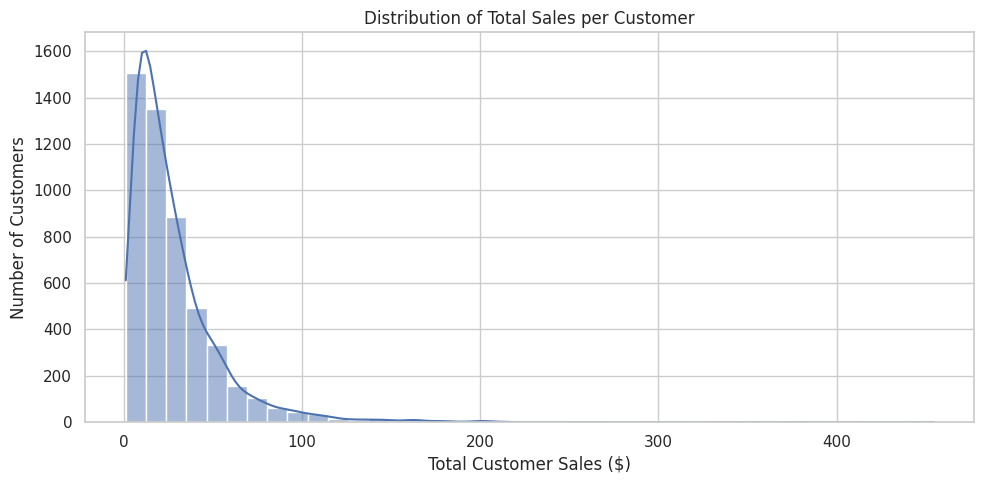

In [7]:
# plot the distribution of sales per customer
plt.figure(figsize=(10, 5))

sns.histplot(
    data=customer_summary,
    x="Total_Sales",
    bins=40,
    kde=True
)

plt.title("Distribution of Total Sales per Customer")
plt.xlabel("Total Customer Sales ($)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

,Product Name,Total_Sales,Total_Profit,Total_Units,Transactions
0,Wonka Bar - Triple Dazzle Caramel,28485.00,18610.20,7596,2015
1,Wonka Bar -Scrumdiddlyumptious,27874.80,19357.50,7743,2064
2,Wonka Bar - Milk Chocolate,26867.75,17443.37,8267,2137
3,Wonka Bar - Fudge Mallows,24890.40,16593.60,6914,1818
4,Wonka Bar - Nutty Crunch Surprise,23574.95,16819.95,6755,1810
5,Lickable Wallpaper,7860.00,3930.00,393,94
6,Kazookles,1205.75,92.75,371,96
7,Wonka Gum,597.50,310.70,478,120
8,Everlasting Gobstopper,130.00,104.00,13,3
9,Fizzy Lifting Drinks,78.75,47.25,21,6


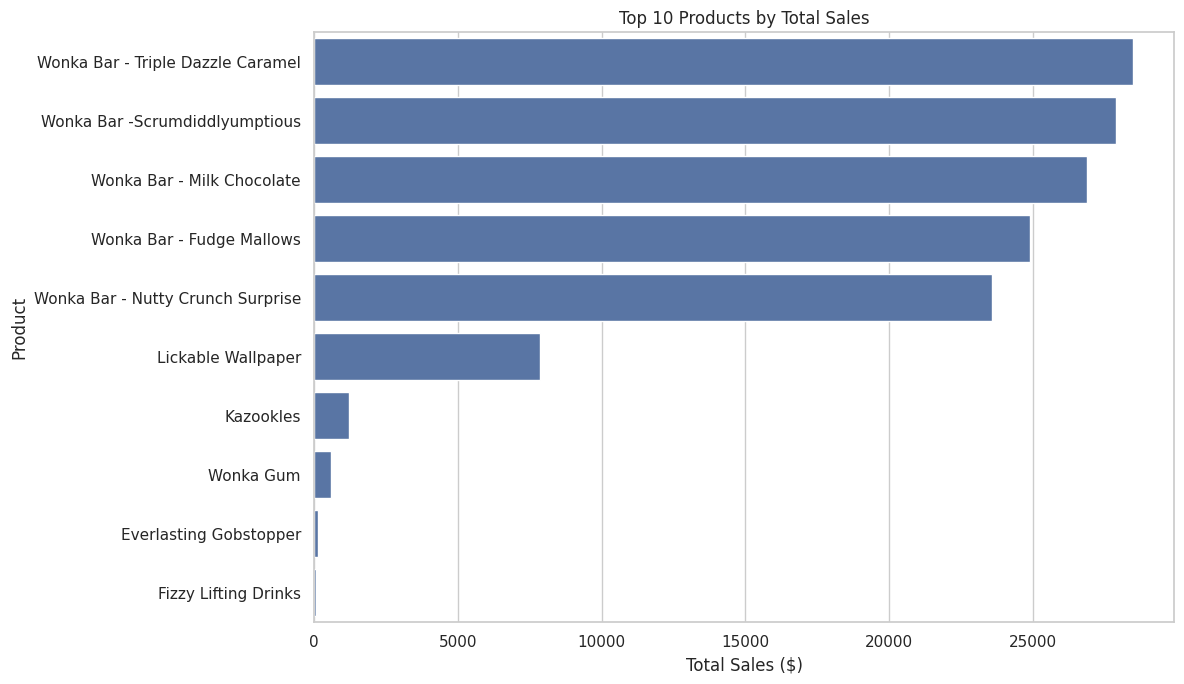

In [8]:
# Product performance analysis
product_sales = (
    df.groupby("Product Name")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Gross Profit", "sum"),
        Total_Units=("Units", "sum"),
        Transactions=("Row ID", "count")
    )
    .sort_values("Total_Sales", ascending=False)
    .reset_index()
)

display(product_sales)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=product_sales.head(10),
    x="Total_Sales",
    y="Product Name"
)

plt.title("Top 10 Products by Total Sales")
plt.xlabel("Total Sales ($)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

,Region,Total_Sales,Total_Profit,Total_Units,Customers
0,Pacific,46301.53,30485.94,12466,1614
1,Atlantic,41197.24,26973.70,11159,1435
2,Interior,32037.60,21282.49,8820,1176
3,Gulf,22247.26,14700.67,6209,822


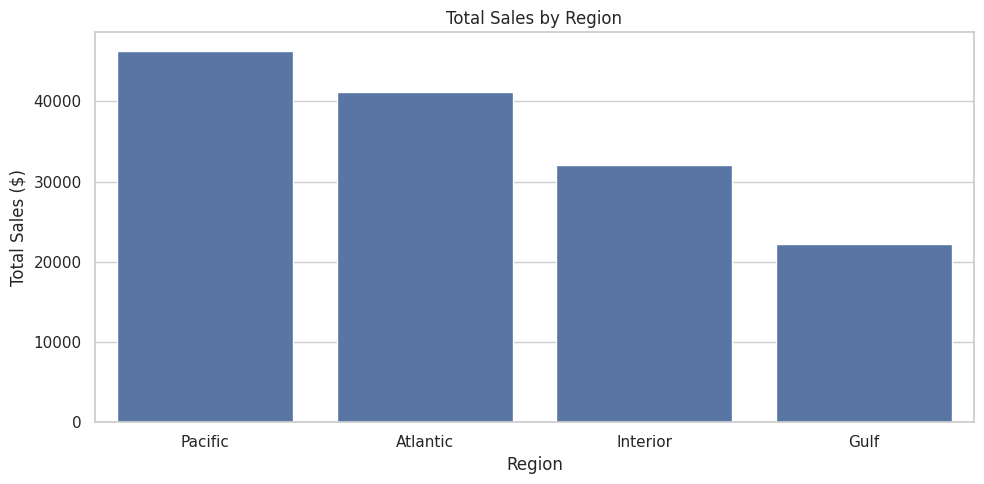

In [9]:
# Geographic sales analysis
region_sales = (
    df.groupby("Region")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Gross Profit", "sum"),
        Total_Units=("Units", "sum"),
        Customers=("Customer ID", "nunique")
    )
    .sort_values("Total_Sales", ascending=False)
    .reset_index()
)

display(region_sales.round(2))

plt.figure(figsize=(10, 5))

sns.barplot(
    data=region_sales,
    x="Region",
    y="Total_Sales"
)

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales ($)")
plt.tight_layout()
plt.show()

In [10]:
# Country-level comparison
country_sales = (
    df.groupby("Country/Region")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Gross Profit", "sum"),
        Customers=("Customer ID", "nunique")
    )
    .reset_index()
)

display(country_sales.round(2))

,Country/Region,Total_Sales,Total_Profit,Customers
0,Canada,2953.29,1934.57,63
1,United States,138830.34,91508.23,5009


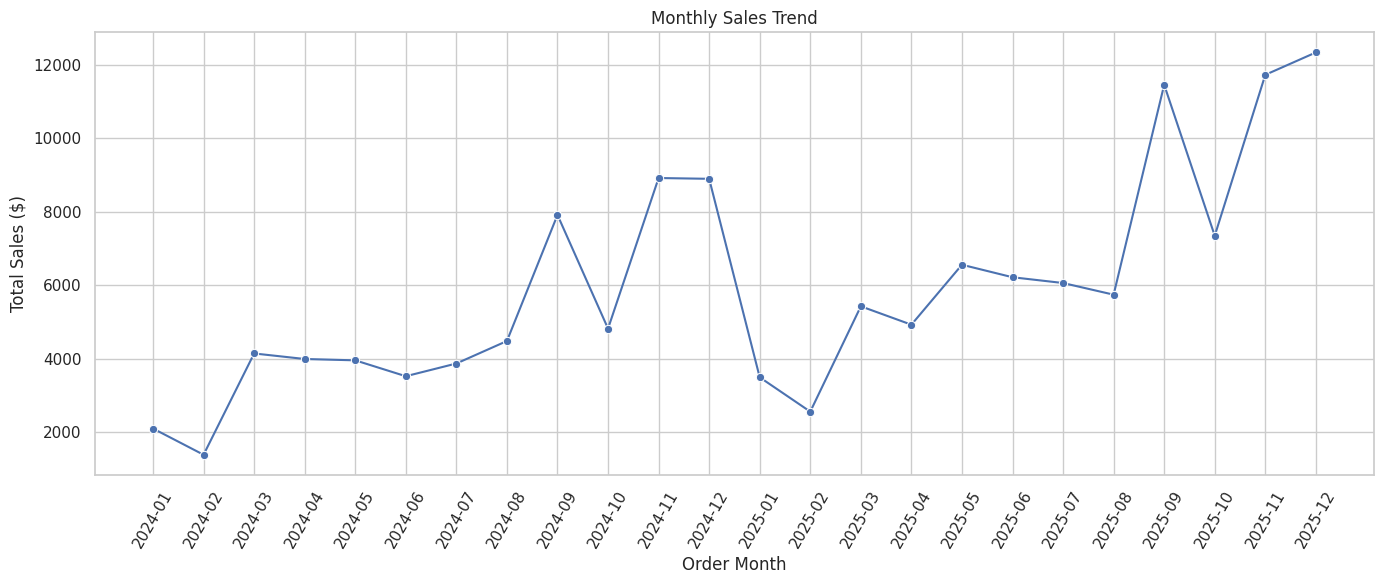

,Order_Month,Total_Sales,Total_Profit,Total_Units
0,2024-01,2093.90,1366.14,566
1,2024-02,1379.87,908.59,398
2,2024-03,4138.90,2671.16,1125
3,2024-04,3988.22,2612.81,1079
4,2024-05,3951.52,2615.44,1099
5,2024-06,3518.76,2330.72,1010
6,2024-07,3865.38,2565.26,1107
7,2024-08,4477.65,2945.87,1227
8,2024-09,7912.10,5206.70,2105
9,2024-10,4815.98,3119.46,1237


In [11]:
# Order trends over time
df["Order_Month"] = (
    df["Order Date"].dt.to_period("M").astype(str)
)

monthly_sales = (
    df.groupby("Order_Month")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Gross Profit", "sum"),
        Total_Units=("Units", "sum")
    )
    .reset_index()
)

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_sales,
    x="Order_Month",
    y="Total_Sales",
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Order Month")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

display(monthly_sales.head(12).round(2))

,Product Name,Total_Sales,Total_Profit,Profit_Margin_Percent
13,Wonka Bar -Scrumdiddlyumptious,27874.80,19357.50,69.44
12,Wonka Bar - Triple Dazzle Caramel,28485.00,18610.20,65.33
10,Wonka Bar - Milk Chocolate,26867.75,17443.37,64.92
11,Wonka Bar - Nutty Crunch Surprise,23574.95,16819.95,71.35
9,Wonka Bar - Fudge Mallows,24890.40,16593.60,66.67
6,Lickable Wallpaper,7860.00,3930.00,50.00
14,Wonka Gum,597.50,310.70,52.00
0,Everlasting Gobstopper,130.00,104.00,80.00
4,Kazookles,1205.75,92.75,7.69
3,Hair Toffee,76.50,59.50,77.78


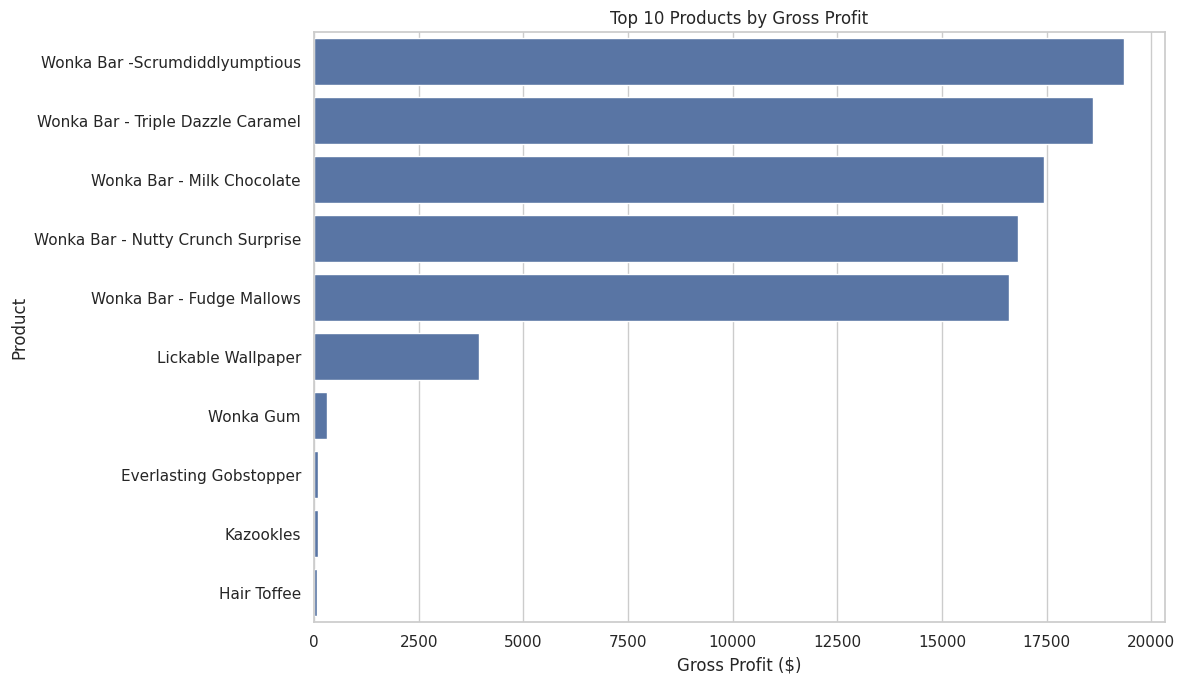

In [12]:
# Profitability analysis
product_profit = (
    df.groupby("Product Name")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Gross Profit", "sum")
    )
    .reset_index()
)

product_profit["Profit_Margin_Percent"] = (
    product_profit["Total_Profit"]
    / product_profit["Total_Sales"] * 100
)

product_profit = product_profit.sort_values(
    "Total_Profit", ascending=False
)

display(product_profit.round(2))

plt.figure(figsize=(12, 7))

sns.barplot(
    data=product_profit.head(10),
    x="Total_Profit",
    y="Product Name"
)

plt.title("Top 10 Products by Gross Profit")
plt.xlabel("Gross Profit ($)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

,Ship Mode,Transactions,Total_Sales,Total_Profit
0,Standard Class,6120,85490.35,56424.46
1,Second Class,1979,27860.22,18306.52
2,First Class,1548,21319.39,14011.09
3,Same Day,547,7113.67,4700.73


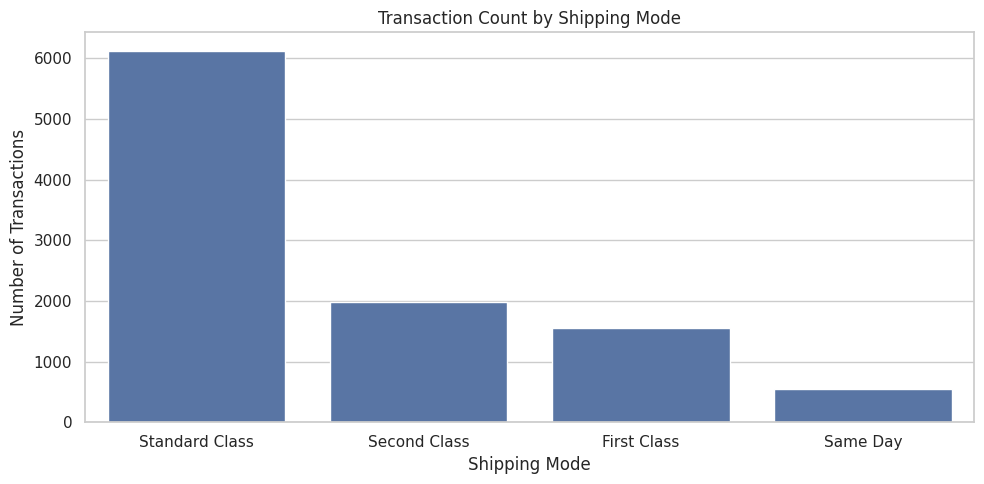

In [13]:
# Analyze shipping mode
ship_mode_analysis = (
    df.groupby("Ship Mode")
    .agg(
        Transactions=("Row ID", "count"),
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Gross Profit", "sum")
    )
    .sort_values("Total_Sales", ascending=False)
    .reset_index()
)

display(ship_mode_analysis.round(2))

plt.figure(figsize=(10, 5))

sns.barplot(
    data=ship_mode_analysis,
    x="Ship Mode",
    y="Transactions"
)

plt.title("Transaction Count by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

,Sales,Units,Gross Profit,Cost
Sales,1.000,0.729,0.976,0.959
Units,0.729,1.000,0.816,0.563
Gross Profit,0.976,0.816,1.000,0.875
Cost,0.959,0.563,0.875,1.000


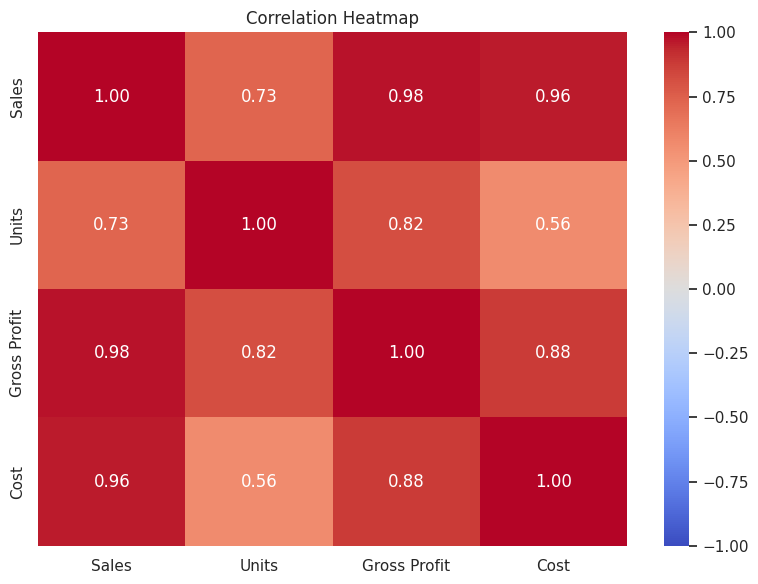

In [14]:
# Correlation analysis
corr_cols = ["Sales", "Units", "Gross Profit", "Cost"]

correlation = df[corr_cols].corr()

display(correlation.round(3))

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [15]:
# Export the EDA results
customer_summary.to_csv(
    "Customer_Level_Analysis.csv",
    index=False
)

product_sales.to_csv(
    "Product_Sales_Analysis.csv",
    index=False
)

region_sales.to_csv(
    "Region_Sales_Analysis.csv",
    index=False
)

monthly_sales.to_csv(
    "Monthly_Sales_Analysis.csv",
    index=False
)

print("EDA analysis files exported successfully!")

EDA analysis files exported successfully!
